# TP 2 : Apprentissage Profond avec TensorFlow / Keras
## Exercice 1 : Reconnaissance de chiffres manuscrits (MNIST)

### 1. Import des bibliothèques

In [1]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Flatten
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt
import numpy as np

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.22.0-rc0


#### Réponses aux questions (Étape 1) :
1. **Quelle est la différence entre TensorFlow et Keras ?**
   * **TensorFlow** est le moteur de calcul bas-niveau (développé par Google) qui manipule les tenseurs, calcule les gradients et exécute les opérations sur CPU ou GPU.
   * **Keras** (`tf.keras`) est l'interface (API) haut-niveau intégrée à TensorFlow qui permet de construire, assembler et entraîner des réseaux de neurones de manière simple, modulaire et intuitive en quelques lignes de code.
2. **À quoi sert la couche `Flatten` dans un réseau de neurones ?**
   * Elle sert à "aplatir" une matrice multidimensionnelle (comme une image 2D de $28 \times 28$ pixels) en un seul vecteur unidimensionnel (1D de $784$ valeurs) afin de pouvoir l'envoyer dans les couches de neurones classiques (`Dense`).
3. **Quelle version de TensorFlow est installée sur votre machine ?**
   * La version installée est affichée ci-dessus en sortie de cellule 2.22.0-rc0.
4. **À quoi servent `Sequential` et `Dense` ?**
   * **`Sequential`** est une structure qui permet d'empiler les couches du réseau de neurones de façon linéaire, les unes après les autres (la sortie d'une couche devient l'entrée de la suivante).
   * **`Dense`** représente une couche de neurones "entièrement connectée" (*fully connected*) : chaque neurone de cette couche est relié à tous les neurones de la couche précédente.

### 2. Chargement et préparation du dataset

In [3]:
# Chargement des données MNIST (téléchargement automatique au 1er lancement)
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Vérification du type avant normalisation
print("Type initial des pixels :", x_train.dtype)

# Normalisation des valeurs des pixels entre 0 et 1
x_train = x_train / 255.0
x_test = x_test / 255.0

print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)
print("x_test shape:", x_test.shape)
print("Type après normalisation :", x_train.dtype)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Type initial des pixels : uint8
x_train shape: (60000, 28, 28)
y_train shape: (60000,)
x_test shape: (10000, 28, 28)
Type après normalisation : float64


#### Réponses aux questions (Étape 2) :
1. **Pourquoi normalise-t-on les valeurs des pixels ?**
   * Initialement, les pixels ont des valeurs entières comprises entre $0$ (noir) et $255$ (blanc). Les ramener sur une échelle réduite entre $0.0$ et $1.0$ stabilise les calculs mathématiques (produits matriciels) et permet à l'algorithme de descente de gradient de converger beaucoup plus rapidement lors de l'entraînement.
2. **Quelle est la taille d'une image et son type de données ?**
   * Chaque image a une taille de **$28 \times 28$ pixels** (en niveaux de gris). Son type de données initial est `uint8` (entier non signé sur 8 bits), qui devient `float64` après la division par `255.0`.
3. **Combien d'exemples contient le jeu d'entraînement ?**
   * Comme l'indique `x_train.shape` `(60000, 28, 28)`, le jeu d'entraînement contient **60 000 images** (et le jeu de test en contient 10 000, soit 70 000 au total).

### 3. Visualisation d'échantillons

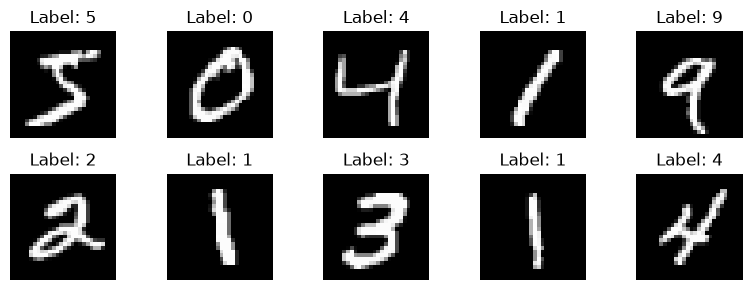

In [4]:
plt.figure(figsize=(8, 3))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

#### Réponses aux questions (Étape 3) :
* **Observation :** Les 10 premiers chiffres affichés (5, 0, 4, 1, 9, 2, 1, 3, 1, 4) correspondent exactement aux étiquettes (`Label`) affichées au-dessus de chaque image.
1. **Quelle commande permet de modifier le nombre d'images affichées ?**
   * Il faut modifier la valeur dans la boucle `for i in range(N):` (ainsi que la grille dans `plt.subplot(lignes, colonnes, i+1)` pour que la grille puisse accueillir les `N` images).
2. **Que représente l'argument `cmap='gray'` ?**
   * `cmap` signifie *Color Map* (palette de couleurs). L'argument `'gray'` indique à Matplotlib d'afficher la matrice 2D en **niveaux de gris** (du noir au blanc) plutôt qu'avec sa palette de couleurs par défaut (`viridis`, qui affiche en bleu/vert/jaune).
3. **Quelle utilité a cette étape dans un projet d'IA ?**
   * C'est une étape cruciale de contrôle qualité (*sanity check*) : elle permet de vérifier visuellement que les images ne sont pas corrompues, que la normalisation n'a pas altéré le visuel, et surtout que les étiquettes (`y_train`) sont bien alignées avec les bonnes images (`x_train`) avant de lancer un entraînement coûteux.

### 4. Construction du modèle de réseau de neurones

In [5]:
model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

#### Réponses aux questions (Étape 4) :
1. **Combien de paramètres le modèle contient-il ?**
   * Le modèle contient exactement **101 770 paramètres** entraînables :
     * Couche `Flatten` : $0$ paramètre (simple redimensionnement $28 \times 28 = 784$).
     * 1ère couche `Dense` (cachée) : $(784 \text{ entrées} \times 128 \text{ neurones}) + 128 \text{ biais} = 100\,480$ paramètres.
     * 2ème couche `Dense` (sortie) : $(128 \text{ entrées} \times 10 \text{ neurones}) + 10 \text{ biais} = 1\,290$ paramètres.
2. **Quelle est la fonction d'activation utilisée dans la couche de sortie ? Pourquoi ?**
   * Il s'agit de la fonction **`softmax`**. On l'utilise pour la classification multiclasse car elle transforme les scores bruts des 10 neurones de sortie en une **distribution de probabilités** (10 valeurs comprises entre $0$ et $1$ dont la somme totale vaut exactement $1$). Le chiffre prédit correspondra au neurone ayant la probabilité la plus élevée.
3. **Quelle est la différence entre ReLU et Softmax ?**
   * **ReLU** (*Rectified Linear Unit*, $f(x) = \max(0, x)$) est utilisée dans les **couches cachées** : elle remplace toutes les valeurs négatives par zéro pour introduire de la non-linéarité tout en évitant la disparition du gradient.
   * **Softmax** est utilisée dans la **couche de sortie** : elle normalise un vecteur de valeurs réelles en probabilités inter-dépendantes pour choisir une classe parmi plusieurs.

### 5. Compilation du modèle

In [6]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
print("Modèle compilé avec succès !")

Modèle compilé avec succès !


#### Réponses aux questions (Étape 5) :
1. **Qu'est-ce qu'un optimiseur ?**
   * C'est l'algorithme mathématique (ici `Adam`) chargé de mettre à jour les poids et les biais du réseau de neurones après chaque lot d'exemples (*batch*), dans le but de réduire l'erreur commise par le modèle.
2. **Pourquoi utilise-t-on une fonction de perte (*loss function*) ?**
   * Elle mesure mathématiquement l'écart (l'erreur) entre la prédiction du réseau et la vraie étiquette (`y_train`). Elle sert de "boussole" à l'optimiseur : l'objectif de l'entraînement est de minimiser cette valeur.
3. **Que se passe-t-il si on change la fonction de perte ?**
   * Si l'on choisit une fonction inadaptée au problème (par exemple `mean_squared_error` pour de la classification ou `categorical_crossentropy` alors que nos labels sont des entiers simples $0$-$9$ et non encodés en *one-hot*), l'entraînement échouera (erreur de dimension) ou le modèle convergera très mal.
4. **Quelle serait la conséquence d'un mauvais choix d'optimiseur ?**
   * Le modèle risque d'apprendre extrêmement lentement, d'osciller sans jamais se stabiliser, ou de rester bloqué dans un "minimum local" (une solution médiocre) avec une faible précision.
5. **Quelle est la différence entre `loss` et `metrics` ?**
   * La **`loss`** (perte) est une fonction mathématique différentiable utilisée directement par l'algorithme de rétropropagation pour **mettre à jour les poids**.
   * Les **`metrics`** (comme l'`accuracy`, le pourcentage de bonnes réponses) servent uniquement à l'**humain** pour évaluer et lire facilement les performances du modèle, sans influencer directement le calcul du gradient.

### 6. Entraînement du modèle

In [8]:
history = model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=32,
    validation_data=(x_test, y_test)
)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.9250 - loss: 0.2612 - val_accuracy: 0.9564 - val_loss: 0.1413
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9659 - loss: 0.1152 - val_accuracy: 0.9706 - val_loss: 0.0979
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9775 - loss: 0.0770 - val_accuracy: 0.9728 - val_loss: 0.0867
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9839 - loss: 0.0563 - val_accuracy: 0.9738 - val_loss: 0.0839
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9880 - loss: 0.0422 - val_accuracy: 0.9751 - val_loss: 0.0833


#### Réponses aux questions (Étape 6) :
* **Observations :** La précision d'entraînement (`accuracy`) augmente rapidement d'une époque à l'autre (passant d'environ 92% à plus de 98%), et la précision de validation (`val_accuracy`) suit une tendance similaire en se stabilisant autour de 97-98%.
1. **Que représente une "époque" (*epoch*) ?**
   * Une époque correspond à un cycle complet durant lequel le réseau de neurones a parcouru l'intégralité du jeu de données d'entraînement (ici les 60 000 images, découpées en paquets de 32 images appelés *batches*).
2. **Pourquoi utilise-t-on un jeu de validation ?**
   * Il permet de contrôler à la fin de chaque époque la capacité de généralisation du modèle sur des données qu'il n'utilise pas pour ajuster ses poids, afin de détecter immédiatement un éventuel surapprentissage (*overfitting*).
3. **Que se passerait-il si on augmentait le nombre d'époques à 50 ?**
   * Le modèle entrerait en **surapprentissage (*overfitting*)** : il finirait par apprendre "par cœur" les images d'entraînement (`accuracy` proche de 100%), mais sa performance sur les nouvelles données (`val_accuracy`) stagnerait voire diminuerait, tandis que la perte de validation (`val_loss`) remonterait.

### 7. Évaluation du modèle

In [9]:
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"Test accuracy: {test_acc:.4f}")
print(f"Test loss: {test_loss:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9751 - loss: 0.0833
Test accuracy: 0.9751
Test loss: 0.0833


#### Réponses aux questions (Étape 7) :
1. **Quelle est la précision finale de votre modèle ?**
   * La précision finale sur le jeu de test (`test_acc`) est de **0.9751** (soit **97.51%**), avec une perte (`test_loss`) de **0.0833**.
2. **Pourquoi la précision du test est souvent inférieure à celle d'entraînement ?**
   * Le modèle ajuste directement ses poids sur les données d'entraînement (où il atteint 98.80%). Lorsqu'il est confronté aux données de test qu'il n'a jamais vues, il rencontre de nouvelles variations d'écriture manuscrite, ce qui entraîne logiquement une légère baisse de performance.
3. **Que faire si le modèle surapprend (*overfitting*) ?**
   * On peut appliquer des techniques de régularisation comme le **Dropout** (désactiver aléatoirement des neurones pendant l'entraînement), le **Early Stopping** (arrêter l'entraînement dès que `val_loss` commence à remonter), la régularisation L1/L2, ou encore la **Data Augmentation**.

### 8. Visualisation des performances

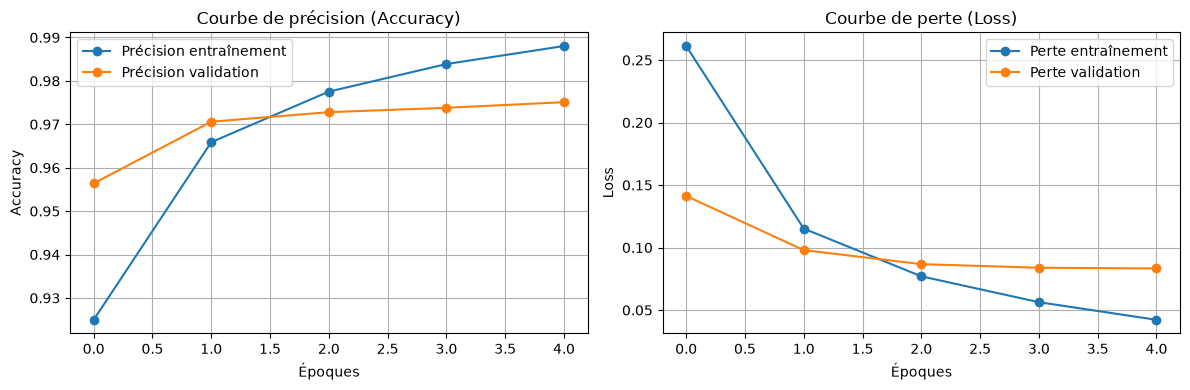

In [10]:
plt.figure(figsize=(12, 4))

# Courbe de précision
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Précision entraînement', marker='o')
plt.plot(history.history['val_accuracy'], label='Précision validation', marker='o')
plt.title('Courbe de précision (Accuracy)')
plt.xlabel('Époques')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Courbe de perte (demandée dans le rapport final)
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Perte entraînement', marker='o')
plt.plot(history.history['val_loss'], label='Perte validation', marker='o')
plt.title('Courbe de perte (Loss)')
plt.xlabel('Époques')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

#### Réponses aux questions (Étape 8) :
1. **Que remarquez-vous sur les deux courbes ?**
   * Les deux courbes de précision augmentent de concert, mais la précision d'entraînement dépasse celle de validation dès la 2ème époque et continue de monter vers 99%, tandis que la validation commence à plafonner autour de 97.5%.
2. **Comment détecter visuellement un surapprentissage ?**
   * On le détecte lorsque la courbe d'entraînement continue de s'améliorer (`accuracy` monte vers 1.0, `loss` descend vers 0) alors que la courbe de validation stagne ou se dégrade (`val_accuracy` baisse et `val_loss` remonte en formant un "U").
3. **Quelle stratégie pourrait-on utiliser pour y remédier ?**
   * Ajouter une couche `Dropout(0.2)` après la couche `Dense(128)`, réduire légèrement le nombre de neurones, ou utiliser un callback `EarlyStopping`.
4. **Que faire si les deux courbes divergent ?**
   * Il faut interrompre l'entraînement à l'époque où les courbes commencent à diverger (ici autour de l'époque 4 ou 5) et renforcer la régularisation ou augmenter la taille du jeu de données.

### 9. Prédictions et visualisation

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


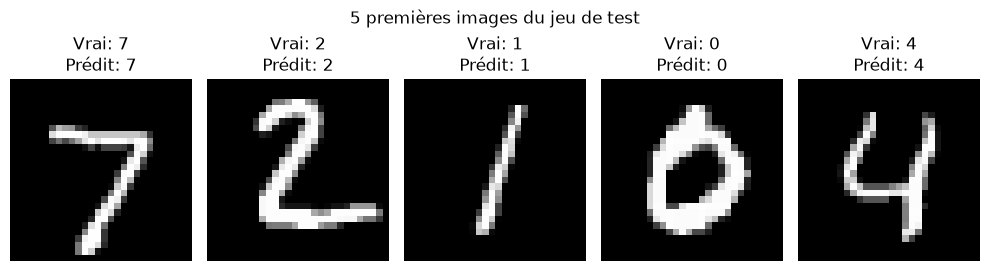

Nombre total d'erreurs sur 10 000 images : 249


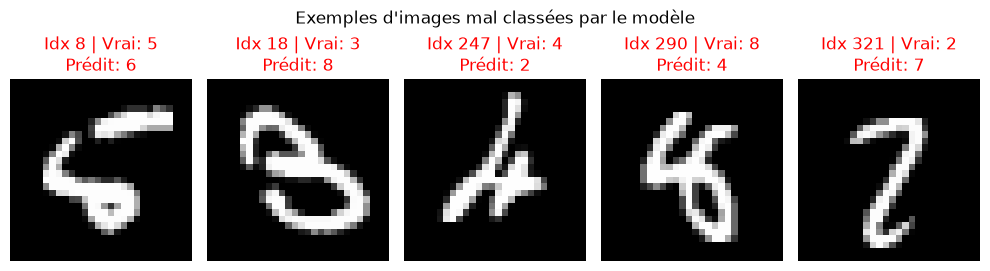

In [11]:
predictions = model.predict(x_test)
y_pred = np.argmax(predictions, axis=1)

# 1. Affichage des 5 premières images de test
plt.figure(figsize=(10, 3))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_test[i], cmap='gray')
    plt.title(f"Vrai: {y_test[i]}\nPrédit: {y_pred[i]}")
    plt.axis('off')
plt.suptitle("5 premières images du jeu de test")
plt.tight_layout()
plt.show()

# 2. Recherche et affichage de 5 erreurs commises par le modèle
erreurs_idx = np.where(y_pred != y_test)[0]
print(f"Nombre total d'erreurs sur 10 000 images : {len(erreurs_idx)}")

plt.figure(figsize=(10, 3))
for i, idx in enumerate(erreurs_idx[:5]):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_test[idx], cmap='gray')
    plt.title(f"Idx {idx} | Vrai: {y_test[idx]}\nPrédit: {y_pred[idx]}", color='red')
    plt.axis('off')
plt.suptitle("Exemples d'images mal classées par le modèle")
plt.tight_layout()
plt.show()

#### Réponses aux questions (Étape 9) :
1. **Le modèle fait-il des erreurs ? Sur quelles images ?**
   * Sur les 5 premières images du test (7, 2, 1, 0, 4), le modèle ne fait aucune erreur. En revanche, sur l'ensemble des 10 000 images de test, il se trompe sur environ 249 images (soit 2.49% d'erreur), notamment sur des chiffres manuscrits ambigus ou mal formés (ex: confusion entre un `4` et un `9`, un `5` et un `6`, ou un `2` et un `7`).
2. **Comment expliquer une prédiction erronée ?**
   * Certains chiffres sont écrits de manière très atypique, inclinée ou incomplète. De plus, la couche `Flatten()` détruit la structure spatiale 2D de l'image : le réseau Dense traite les 784 pixels indépendamment sans comprendre les notions de "contours" ou de "voisinage" local.
3. **Quelle technique permettrait d'améliorer la précision (ex: CNN) ?**
   * L'utilisation d'un **Réseau de Neurones Convolutif (CNN)** avec des couches `Conv2D` et `MaxPooling2D` permettrait d'extraire les caractéristiques spatiales (bords, boucles, courbes) et d'atteindre facilement plus de 99% de précision sur MNIST.

---

### Analyse 
Ce premier exercice sur le dataset MNIST démontre l'efficacité d'un réseau de neurones entièrement connecté (ANN) simple, qui parvient à atteindre une précision remarquable de **97.51%** sur le jeu de test en seulement 5 époques d'entraînement. L'analyse des courbes d'apprentissage révèle une convergence très rapide grâce à la normalisation préalable des pixels entre 0 et 1 et à l'optimiseur Adam. La principale limite rencontrée réside dans l'aplatissement des images (`Flatten`), qui fait perdre l'information géométrique 2D et provoque environ 250 erreurs sur des chiffres manuscrits ambigus ou décentrés. De plus, un début d'écart entre la précision d'entraînement (98.80%) et de validation (97.51%) signale l'apparition progressive d'un léger surapprentissage. Pour améliorer ce modèle, il serait pertinent d'intégrer des couches de régularisation (`Dropout`), d'utiliser un *Learning Rate Scheduler*, et surtout de remplacer cette architecture Dense par un réseau convolutif (**CNN**) couplé à de la *Data Augmentation* (légères rotations et zooms).